# ỨNG DỤNG 2 — DỰ ĐOÁN GIÁ NHÀ

Notebook tái hiện **mục 3** của báo cáo `A02_CT_khoipv.447.pdf`: bài toán hồi quy dự đoán giá
bán nhà từ 5 đặc trưng, so sánh 4 mô hình (Linear Regression, Decision Tree, Random Forest, SVR)
và lưu weight + preprocessor cho tầng triển khai (`REST_API.py`).

| Mục báo cáo | Nội dung | Mục notebook |
| --- | --- | --- |
| 3.1 | Mô tả bài toán và dữ liệu | 1 – 2 |
| 3.2 | Làm sạch, biểu diễn và EDA | 3 – 4 |
| 3.3 | Phát triển, đánh giá và chọn mô hình | 5 – 9 |
| 3.4 | Triển khai (lưu weight, gọi API) | 10 – 11 |

## 1. Mô tả bài toán và dữ liệu

**Bài toán.** Hồi quy — dự đoán `Price` (đơn vị **tỷ VNĐ**) của một tin rao bán nhà.

**Biểu diễn dữ liệu.** Mỗi căn nhà là một vector gồm **3 biến số** và **2 biến phân loại đã
mã hoá** (mục 1 của báo cáo: *"Biến số + biến category (đã one-hot/encode)"*):

| Đặc trưng | Kiểu | Ý nghĩa |
| --- | --- | --- |
| `Floors` | Số | Số tầng |
| `Bedrooms` | Số | Số phòng ngủ |
| `Bathrooms` | Số | Số phòng vệ sinh |
| `Legal status` | Phân loại | Tình trạng pháp lý (sổ đỏ / hợp đồng mua bán / chưa rõ) |
| `Furniture state` | Phân loại | Tình trạng nội thất (đầy đủ / cơ bản / chưa rõ) |
| `Price` | Số | **Biến mục tiêu** — giá bán (tỷ VNĐ) |

**Chỉ số đánh giá.** MAE (sai số tuyệt đối trung bình), RMSE (căn bậc hai sai số bình phương
trung bình — phạt nặng sai số lớn) và R² (tỷ lệ phương sai giải thích được).

In [1]:
import json
import pickle
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
matplotlib.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid")

CANDIDATES = [
    Path("../data/vietnam_housing_dataset.csv"),
    Path("data/vietnam_housing_dataset.csv"),
    Path("src/Assignment 02/house_price/data/vietnam_housing_dataset.csv"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Khong tim thay dataset. Da thu: " + "; ".join(map(str, CANDIDATES)))
DATA_PATH = DATA_PATH.resolve()

APP_DIR = DATA_PATH.parent.parent          # .../house_price
MODEL_DIR = APP_DIR / "models"
FIGURE_DIR = APP_DIR / "report" / "figures"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / name, bbox_inches="tight")


print("Du lieu :", DATA_PATH)
print("Weight  :", MODEL_DIR)
print("Hinh ve :", FIGURE_DIR)

Du lieu : /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 02/house_price/data/vietnam_housing_dataset.csv
Weight  : /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 02/house_price/models
Hinh ve : /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 02/house_price/report/figures


## 2. Nạp dữ liệu

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Kich thuoc:", df_raw.shape)
df_raw.head()

Kich thuoc: (30229, 12)


,Address,Area,Frontage,Access Road,House direction,Balcony direction,Floors,Bedrooms,Bathrooms,Legal status,Furniture state,Price
0,"Dự án The Empire - Vinhomes Ocean Park 2, Xã L...",84.0,NaN,NaN,NaN,NaN,4.0,NaN,NaN,Have certificate,NaN,8.60
1,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",60.0,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,7.50
2,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",90.0,6.0,13.0,Đông - Bắc,Đông - Bắc,5.0,NaN,NaN,Sale contract,NaN,8.90
3,"Đường Nguyễn Văn Khối, Phường 11, Gò Vấp, Hồ C...",54.0,NaN,3.5,Tây - Nam,Tây - Nam,2.0,2.0,3.0,Have certificate,Full,5.35
4,"Đường Quang Trung, Phường 8, Gò Vấp, Hồ Chí Minh",92.0,NaN,NaN,Đông - Nam,Đông - Nam,2.0,4.0,4.0,Have certificate,Full,6.90


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 30229 entries, 0 to 30228
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Address            30229 non-null  str    
 1   Area               30229 non-null  float64
 2   Frontage           18665 non-null  float64
 3   Access Road        16932 non-null  float64
 4   House direction    8990 non-null   str    
 5   Balcony direction  5246 non-null   str    
 6   Floors             26626 non-null  float64
 7   Bedrooms           25067 non-null  float64
 8   Bathrooms          23155 non-null  float64
 9   Legal status       25723 non-null  str    
 10  Furniture state    16110 non-null  str    
 11  Price              30229 non-null  float64
dtypes: float64(7), str(5)
memory usage: 2.8 MB


In [4]:
# Ty le gia tri thieu cua tung cot
missing = (df_raw.isna().mean() * 100).sort_values(ascending=False).round(2)
missing.to_frame("Ty le thieu (%)")

,Ty le thieu (%)
Balcony direction,82.65
House direction,70.26
Furniture state,46.71
Access Road,43.99
Frontage,38.25
Bathrooms,23.40
Bedrooms,17.08
Legal status,14.91
Floors,11.92
Address,0.00


=> Các cột như `Frontage`, `House direction`, `Balcony direction` thiếu rất nhiều nên không
được đưa vào mô hình. Báo cáo chốt 5 đặc trưng: `Floors`, `Bedrooms`, `Bathrooms`,
`Legal status`, `Furniture state`.

## 3. Làm sạch và biểu diễn dữ liệu

Ba bước:

1. Ép kiểu số cho `Floors`, `Bedrooms`, `Bathrooms` và `Price`; bỏ dòng thiếu `Price`.
2. Cắt **1% giá trị cao nhất** của `Price` — vài tin rao hàng trăm tỷ kéo lệch toàn bộ phân phối.
3. Biến phân loại thiếu được điền `"Unknown"` thành một nhóm riêng thay vì bị loại bỏ.

In [5]:
NUMERIC_FEATURES = ["Floors", "Bedrooms", "Bathrooms"]
CATEGORY_FEATURES = ["Legal status", "Furniture state"]
FEATURES = NUMERIC_FEATURES + CATEGORY_FEATURES
TARGET = "Price"

df = df_raw.copy()
for col in NUMERIC_FEATURES + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

before = len(df)
df = df.dropna(subset=[TARGET])
print(f"Bo {before - len(df)} dong thieu Price -> con {len(df)} dong")

price_cap = df[TARGET].quantile(0.99)
df = df[df[TARGET] < price_cap]
print(f"Cat outlier tai nguong {price_cap:.2f} ty VND -> con {len(df)} dong")

for col in NUMERIC_FEATURES:
    df[col] = df[col].fillna(df[col].median())
for col in CATEGORY_FEATURES:
    df[col] = df[col].fillna("Unknown")

print("\nGia tri thieu con lai trong 5 dac trung:", int(df[FEATURES].isna().sum().sum()))
df[FEATURES + [TARGET]].head()

Bo 0 dong thieu Price -> con 30229 dong
Cat outlier tai nguong 10.00 ty VND -> con 29743 dong

Gia tri thieu con lai trong 5 dac trung: 0


,Floors,Bedrooms,Bathrooms,Legal status,Furniture state,Price
0,4.0,3.0,3.0,Have certificate,Unknown,8.60
1,5.0,3.0,3.0,Unknown,Unknown,7.50
2,5.0,3.0,3.0,Sale contract,Unknown,8.90
3,2.0,2.0,3.0,Have certificate,Full,5.35
4,2.0,4.0,4.0,Have certificate,Full,6.90


In [6]:
df[NUMERIC_FEATURES + [TARGET]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Floors,29743.0,3.355,1.251,1.0,2.0,3.0,4.0,9.00
Bedrooms,29743.0,3.418,1.205,1.0,3.0,3.0,4.0,9.00
Bathrooms,29743.0,3.260,1.233,1.0,3.0,3.0,4.0,9.00
Price,29743.0,5.804,2.165,1.0,4.2,5.8,7.5,9.99


In [7]:
for col in CATEGORY_FEATURES:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()

--- Legal status ---
Legal status
Have certificate    24402
Unknown              4417
Sale contract         924
Name: count, dtype: int64

--- Furniture state ---
Furniture state
Unknown    13849
Full       10429
Basic       5465
Name: count, dtype: int64



## 4. Phân tích khám phá dữ liệu (EDA)

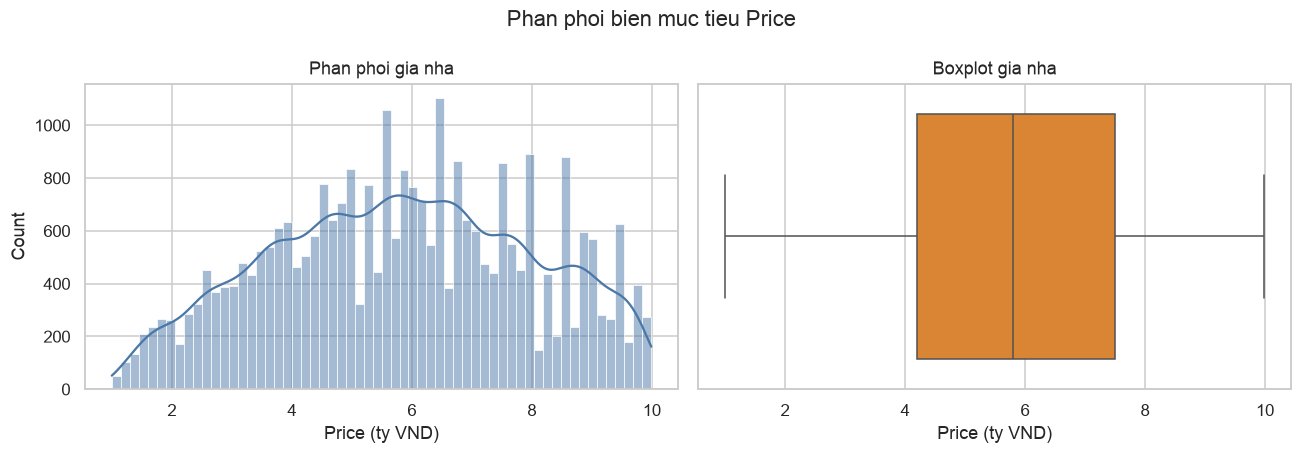

Gia trung binh: 5.80 ty | Trung vi: 5.80 ty


In [8]:
# Phan phoi bien muc tieu Price
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.histplot(df[TARGET], bins=60, kde=True, ax=axes[0], color="#4C78A8")
axes[0].set_title("Phan phoi gia nha")
axes[0].set_xlabel("Price (ty VND)")
sns.boxplot(x=df[TARGET], ax=axes[1], color="#F58518")
axes[1].set_title("Boxplot gia nha")
axes[1].set_xlabel("Price (ty VND)")
plt.suptitle("Phan phoi bien muc tieu Price")
save_figure("house_price_target_distribution.png")
plt.show()

print("Gia trung binh: {:.2f} ty | Trung vi: {:.2f} ty".format(df[TARGET].mean(), df[TARGET].median()))

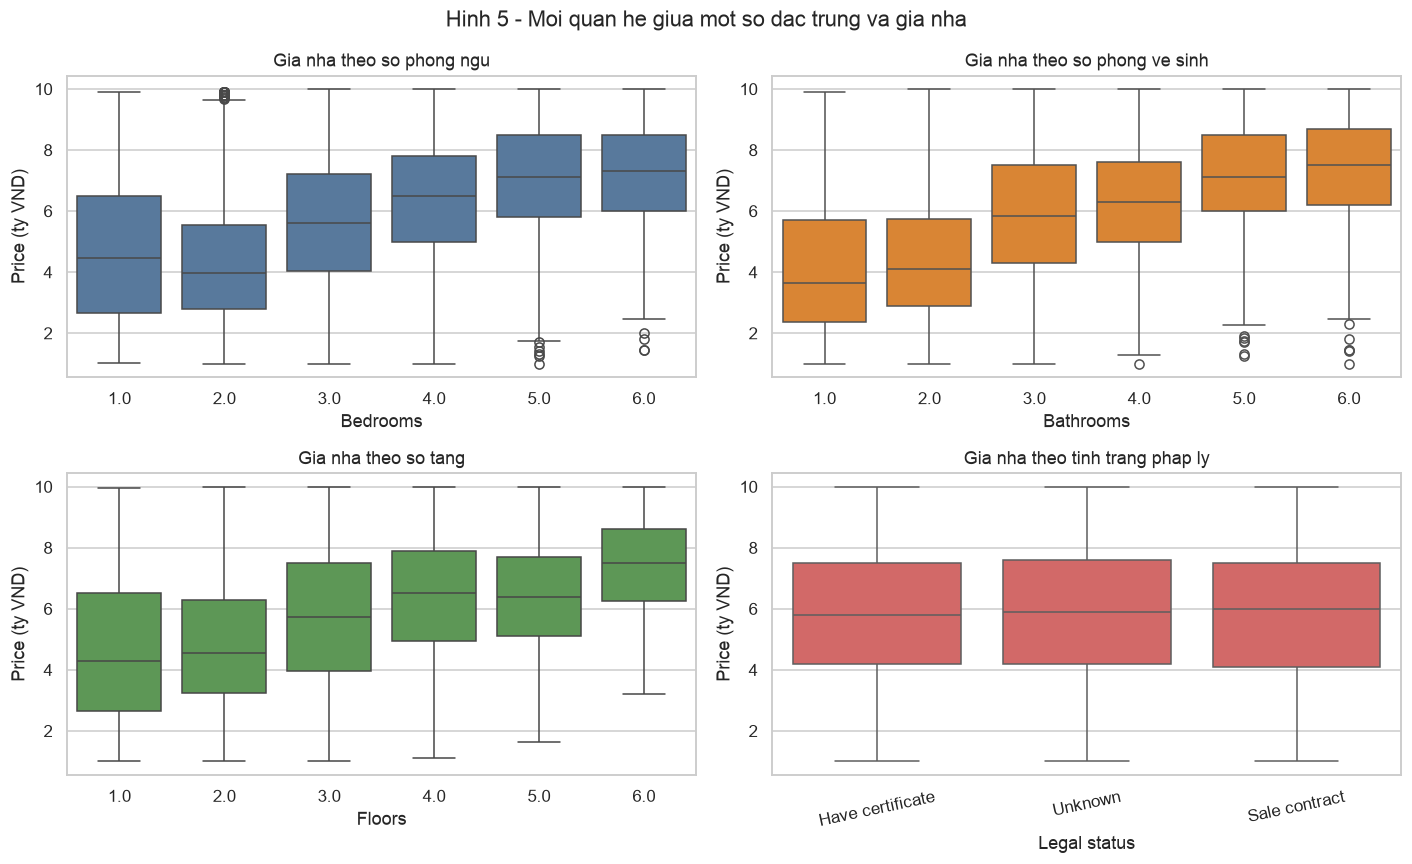

In [9]:
# Hinh 5 cua bao cao: moi quan he giua dac trung va gia nha
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

sns.boxplot(data=df[df["Bedrooms"].between(1, 6)], x="Bedrooms", y=TARGET,
            ax=axes[0, 0], color="#4C78A8")
axes[0, 0].set_title("Gia nha theo so phong ngu")

sns.boxplot(data=df[df["Bathrooms"].between(1, 6)], x="Bathrooms", y=TARGET,
            ax=axes[0, 1], color="#F58518")
axes[0, 1].set_title("Gia nha theo so phong ve sinh")

sns.boxplot(data=df[df["Floors"].between(1, 6)], x="Floors", y=TARGET,
            ax=axes[1, 0], color="#54A24B")
axes[1, 0].set_title("Gia nha theo so tang")

sns.boxplot(data=df, x="Legal status", y=TARGET, ax=axes[1, 1], color="#E45756")
axes[1, 1].set_title("Gia nha theo tinh trang phap ly")
axes[1, 1].tick_params(axis="x", rotation=12)

for ax in axes.ravel():
    ax.set_ylabel("Price (ty VND)")

plt.suptitle("Hinh 5 - Moi quan he giua mot so dac trung va gia nha")
save_figure("house_price_feature_vs_price.png")
plt.show()

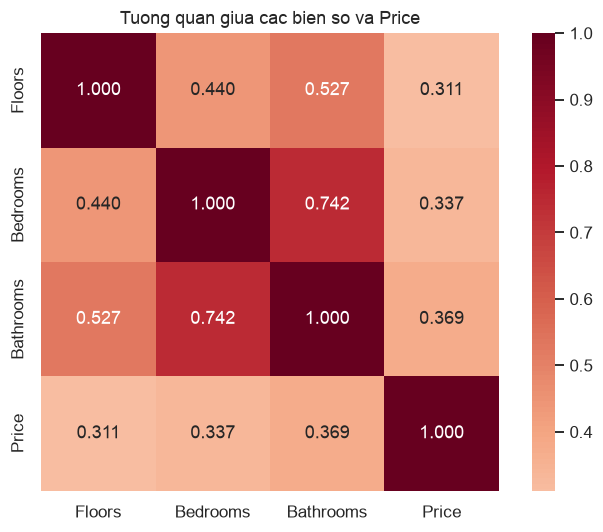

Tuong quan voi Price:
Bathrooms    0.369
Bedrooms     0.337
Floors       0.311
Name: Price, dtype: float64


In [10]:
# Ma tran tuong quan cho cac bien so
plt.figure(figsize=(6.5, 5))
corr = df[NUMERIC_FEATURES + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".3f", cmap="RdBu_r", center=0, square=True)
plt.title("Tuong quan giua cac bien so va Price")
save_figure("house_price_correlation_heatmap.png")
plt.show()

print("Tuong quan voi Price:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

=> `Bathrooms` và `Bedrooms` có quan hệ dương rõ nhất với giá, nhưng hệ số tương quan chỉ ở mức
trung bình — 5 đặc trưng này mô tả được xu hướng chung chứ chưa đủ để giải thích phần lớn biến
động giá (thiếu vị trí, diện tích thực, thời điểm rao). Điều này báo trước R² sẽ không cao.

## 5. Chia tập và xây dựng preprocessor

`ColumnTransformer` gộp hai nhánh:

* **Nhánh số** — `SimpleImputer(median)` rồi `StandardScaler` đưa về cùng thang đo.
* **Nhánh phân loại** — `SimpleImputer(constant="Unknown")` rồi `OneHotEncoder`.

Preprocessor chỉ `fit` trên tập train rồi `transform` tập test. Đây chính là điểm mục 5.1 của
báo cáo nhấn mạnh: **lưu preprocessor ngay sau tập train giúp tránh rò rỉ dữ liệu khi inference
trên API.**

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 2
TEST_SIZE = 0.2

X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]} mau | Test: {X_test.shape[0]} mau")


def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), NUMERIC_FEATURES),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CATEGORY_FEATURES),
    ])


preprocessor = make_preprocessor()
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print(f"\nSo chieu sau one-hot: {X_train_proc.shape[1]}")
print("Ten cot sau bien doi:", list(feature_names))

Train: 23794 mau | Test: 5949 mau

So chieu sau one-hot: 9
Ten cot sau bien doi: ['num__Floors', 'num__Bedrooms', 'num__Bathrooms', 'cat__Legal status_Have certificate', 'cat__Legal status_Sale contract', 'cat__Legal status_Unknown', 'cat__Furniture state_Basic', 'cat__Furniture state_Full', 'cat__Furniture state_Unknown']


## 6. Mô hình cơ sở (baseline)

Luôn dự đoán giá trung bình của tập train. Baseline này có R² ≈ 0 theo định nghĩa.

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
    }


baseline = DummyRegressor(strategy="mean").fit(X_train_proc, y_train)
baseline_metrics = evaluate(y_test, baseline.predict(X_test_proc))

pd.DataFrame([{"Model": "Baseline (gia trung binh)", **baseline_metrics}]).round(4)

,Model,MAE,RMSE,R2
0,Baseline (gia trung binh),1.8106,2.1677,-0.0


## 7. Huấn luyện 4 mô hình hồi quy

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

MODEL_SPECS = {
    "linear_regression": ("Linear Regression", LinearRegression()),
    "decision_tree": ("Decision Tree Regressor", DecisionTreeRegressor(random_state=42)),
    "random_forest": ("Random Forest Regressor", RandomForestRegressor(n_estimators=100, random_state=42)),
    "svr": ("Support Vector Regression", SVR(kernel="rbf")),
}

trained_models, results = {}, []
for key, (display_name, estimator) in MODEL_SPECS.items():
    estimator.fit(X_train_proc, y_train)
    trained_models[key] = estimator

    train_metrics = evaluate(y_train, estimator.predict(X_train_proc))
    test_metrics = evaluate(y_test, estimator.predict(X_test_proc))

    results.append({
        "Key": key, "Model": display_name,
        "MAE": test_metrics["MAE"], "RMSE": test_metrics["RMSE"], "R2": test_metrics["R2"],
        "RMSE_train": train_metrics["RMSE"], "R2_train": train_metrics["R2"],
    })
    print(f"{display_name:28s} test RMSE = {test_metrics['RMSE']:.4f} | R2 = {test_metrics['R2']:.4f}")

results_df = pd.DataFrame(results).set_index("Key")
results_df[["Model", "MAE", "RMSE", "R2"]].round(4)

Linear Regression            test RMSE = 1.9889 | R2 = 0.1582
Decision Tree Regressor      test RMSE = 1.9555 | R2 = 0.1862


Random Forest Regressor      test RMSE = 1.9465 | R2 = 0.1937


Support Vector Regression    test RMSE = 1.9560 | R2 = 0.1858


,Model,MAE,RMSE,R2
Key,,,,
linear_regression,Linear Regression,1.6349,1.9889,0.1582
decision_tree,Decision Tree Regressor,1.5897,1.9555,0.1862
random_forest,Random Forest Regressor,1.5831,1.9465,0.1937
svr,Support Vector Regression,1.5722,1.9560,0.1858


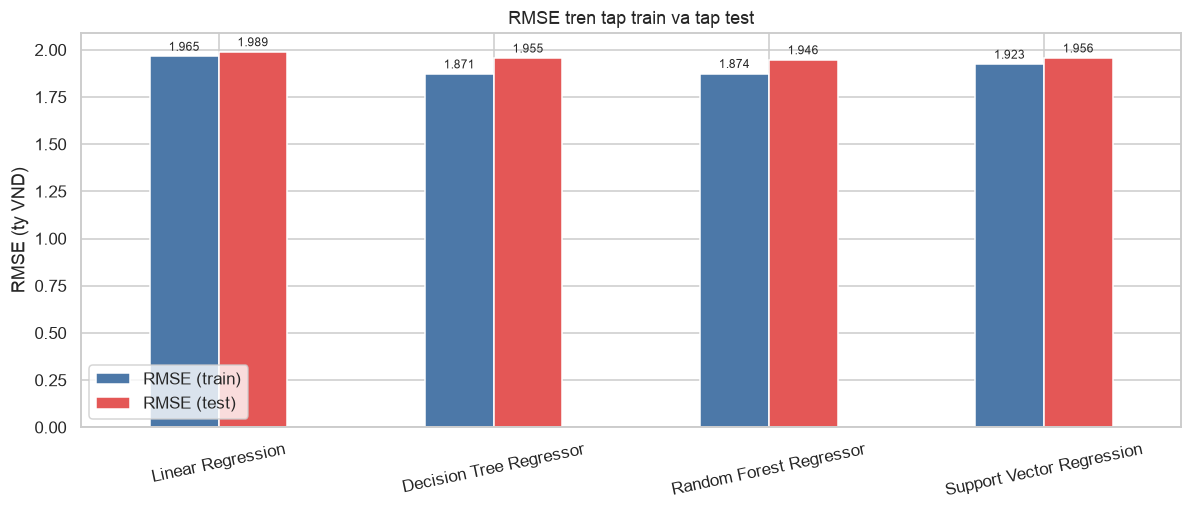

,RMSE (train),RMSE (test),R2 (train),R2 (test)
Model,,,,
Linear Regression,1.9649,1.9889,0.1757,0.1582
Decision Tree Regressor,1.8715,1.9555,0.2523,0.1862
Random Forest Regressor,1.8738,1.9465,0.2504,0.1937
Support Vector Regression,1.9230,1.9560,0.2105,0.1858


In [14]:
# Train vs Test - kiem tra overfitting
compare = results_df.set_index("Model")[["RMSE_train", "RMSE", "R2_train", "R2"]]
compare.columns = ["RMSE (train)", "RMSE (test)", "R2 (train)", "R2 (test)"]

ax = compare[["RMSE (train)", "RMSE (test)"]].plot(
    kind="bar", figsize=(11, 4.8), color=["#4C78A8", "#E45756"])
ax.set_title("RMSE tren tap train va tap test")
ax.set_ylabel("RMSE (ty VND)")
ax.set_xlabel("")
plt.xticks(rotation=12)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)
save_figure("house_price_train_vs_test.png")
plt.show()

display(compare.round(4))

=> Decision Tree có RMSE train rất thấp nhưng RMSE test cao hơn hẳn — dấu hiệu quá khớp. Random
Forest trung bình hoá nhiều cây nên thu hẹp được khoảng cách này.

## 8. Đánh giá và chọn mô hình

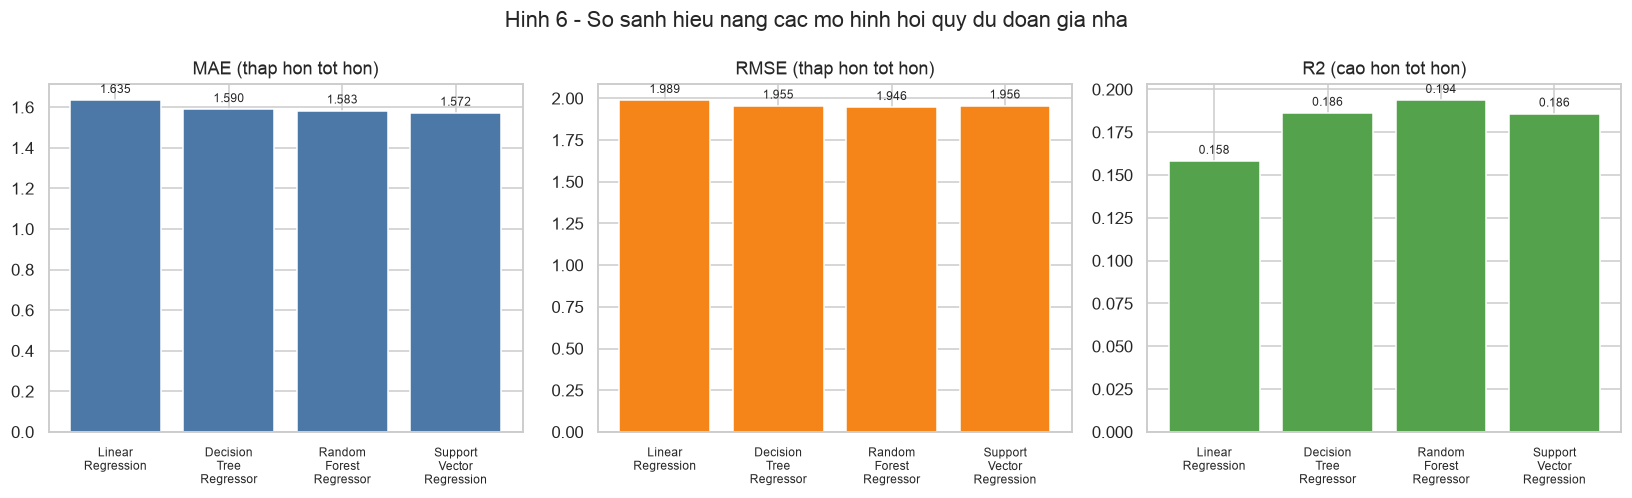

,MAE,RMSE,R2
Model,,,
Random Forest Regressor,1.5831,1.9465,0.1937
Decision Tree Regressor,1.5897,1.9555,0.1862
Support Vector Regression,1.5722,1.9560,0.1858
Linear Regression,1.6349,1.9889,0.1582


In [15]:
# Hinh 6 cua bao cao: so sanh hieu nang 4 mo hinh hoi quy
plot_df = results_df.set_index("Model")[["MAE", "RMSE", "R2"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, metric, color, better in [
    (axes[0], "MAE", "#4C78A8", "thap hon tot hon"),
    (axes[1], "RMSE", "#F58518", "thap hon tot hon"),
    (axes[2], "R2", "#54A24B", "cao hon tot hon"),
]:
    bars = ax.bar(range(len(plot_df)), plot_df[metric].values, color=color)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
    ax.set_xticks(range(len(plot_df)))
    ax.set_xticklabels([n.replace(" ", "\n") for n in plot_df.index], fontsize=8)
    ax.set_title(f"{metric} ({better})")

plt.suptitle("Hinh 6 - So sanh hieu nang cac mo hinh hoi quy du doan gia nha")
save_figure("house_price_model_comparison.png")
plt.show()

display(plot_df.round(4).sort_values("R2", ascending=False))

In [16]:
BEST_RMSE_KEY = results_df["RMSE"].idxmin()
BEST_MAE_KEY = results_df["MAE"].idxmin()

print("Tot nhat ve RMSE/R2 : {} (RMSE = {:.3f}, R2 = {:.3f})".format(
    results_df.loc[BEST_RMSE_KEY, "Model"],
    results_df.loc[BEST_RMSE_KEY, "RMSE"],
    results_df.loc[BEST_RMSE_KEY, "R2"]))
print("Tot nhat ve MAE     : {} (MAE = {:.3f})".format(
    results_df.loc[BEST_MAE_KEY, "Model"],
    results_df.loc[BEST_MAE_KEY, "MAE"]))

Tot nhat ve RMSE/R2 : Random Forest Regressor (RMSE = 1.946, R2 = 0.194)
Tot nhat ve MAE     : Support Vector Regression (MAE = 1.572)


=> Khớp với kết quả nêu ở mục 3.3 của báo cáo: **Random Forest đạt RMSE ≈ 1.946 và R² ≈ 0.194**
(tốt nhất), trong khi **SVR có MAE thấp nhất ≈ 1.58**. Hai chỉ số cho hai quán quân khác nhau vì
RMSE phạt nặng các sai số lớn còn MAE đối xử đều với mọi sai số.

R² chỉ quanh 0.19 — 5 đặc trưng này giải thích được khoảng một phần năm biến động giá. Phần còn
lại nằm ở những yếu tố không có trong vector đầu vào, trước hết là **vị trí** và **diện tích**.

## 9. Khảo sát siêu tham số

Vì Decision Tree là model mặc định khi deploy (mục 3.3 của báo cáo), cần biết `max_depth` ảnh
hưởng thế nào tới đánh đổi thiên lệch – phương sai.

max_depth =    3 -> R2 (5-fold CV) = 0.1714
max_depth =    5 -> R2 (5-fold CV) = 0.1926
max_depth =    7 -> R2 (5-fold CV) = 0.1974
max_depth =   10 -> R2 (5-fold CV) = 0.1892
max_depth =   15 -> R2 (5-fold CV) = 0.1807
max_depth =   20 -> R2 (5-fold CV) = 0.1800


max_depth = None -> R2 (5-fold CV) = 0.1800


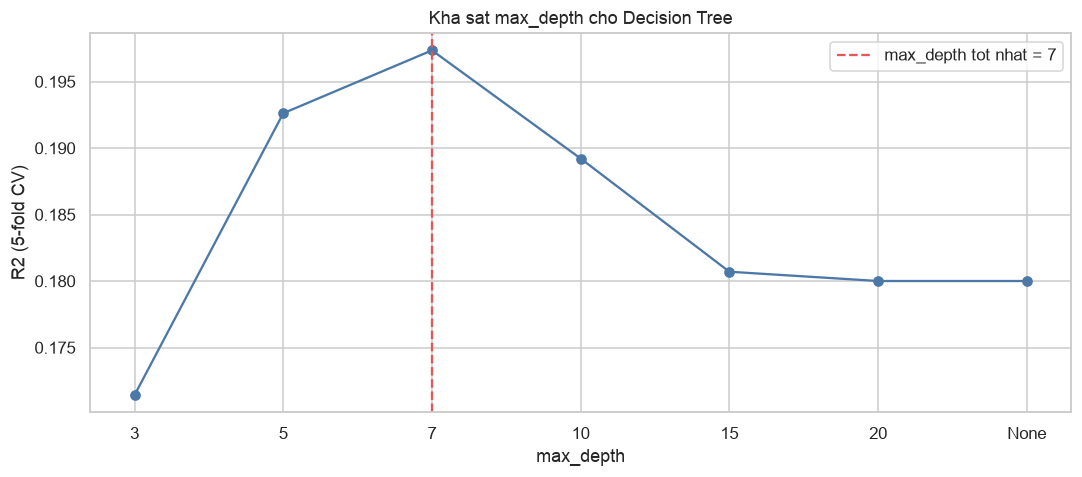

In [17]:
from sklearn.model_selection import cross_val_score

depths = [3, 5, 7, 10, 15, 20, None]
depth_scores = []
for depth in depths:
    score = cross_val_score(
        DecisionTreeRegressor(max_depth=depth, random_state=42),
        X_train_proc, y_train, cv=5, scoring="r2",
    ).mean()
    depth_scores.append(score)
    print(f"max_depth = {str(depth):>4s} -> R2 (5-fold CV) = {score:.4f}")

labels = [str(d) for d in depths]
plt.figure(figsize=(10, 4.5))
plt.plot(labels, depth_scores, marker="o", color="#4C78A8")
best_label = labels[int(np.argmax(depth_scores))]
plt.axvline(best_label, color="#E45756", linestyle="--", label=f"max_depth tot nhat = {best_label}")
plt.title("Kha sat max_depth cho Decision Tree")
plt.xlabel("max_depth")
plt.ylabel("R2 (5-fold CV)")
plt.legend()
save_figure("house_price_dt_max_depth.png")
plt.show()

n_estimators =  10 -> R2 (5-fold CV) = 0.1909


n_estimators =  25 -> R2 (5-fold CV) = 0.1931


n_estimators =  50 -> R2 (5-fold CV) = 0.1937


n_estimators = 100 -> R2 (5-fold CV) = 0.1936


n_estimators = 150 -> R2 (5-fold CV) = 0.1938


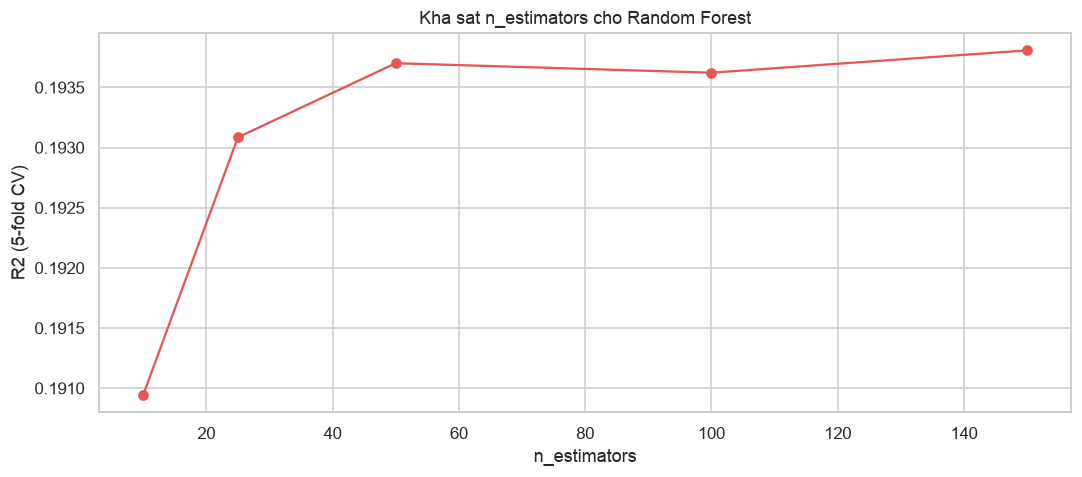

In [18]:
# Kha sat n_estimators cho Random Forest
n_trees = [10, 25, 50, 100, 150]
tree_scores = []
for n in n_trees:
    score = cross_val_score(
        RandomForestRegressor(n_estimators=n, random_state=42),
        X_train_proc, y_train, cv=5, scoring="r2",
    ).mean()
    tree_scores.append(score)
    print(f"n_estimators = {n:3d} -> R2 (5-fold CV) = {score:.4f}")

plt.figure(figsize=(10, 4.5))
plt.plot(n_trees, tree_scores, marker="o", color="#E45756")
plt.title("Kha sat n_estimators cho Random Forest")
plt.xlabel("n_estimators")
plt.ylabel("R2 (5-fold CV)")
save_figure("house_price_rf_n_estimators.png")
plt.show()

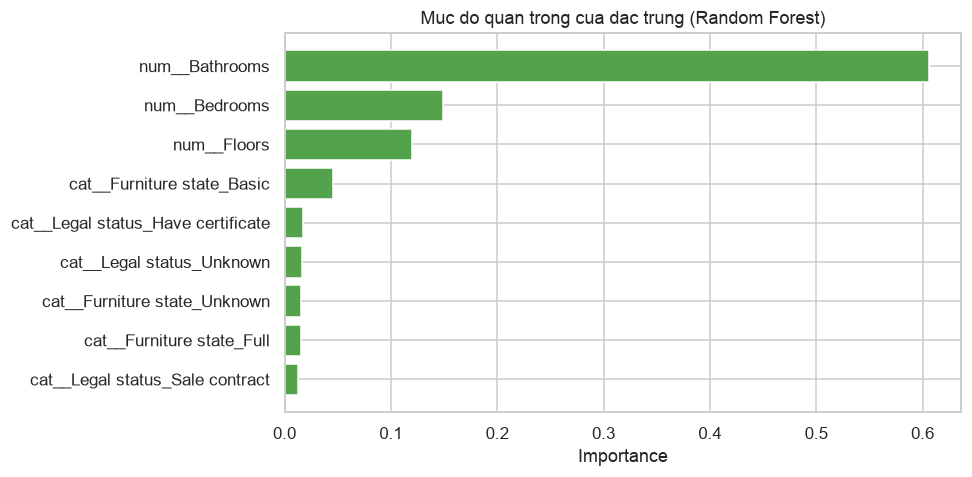

,Importance
num__Bathrooms,0.6062
num__Bedrooms,0.1494
num__Floors,0.1203
cat__Furniture state_Basic,0.0460
cat__Legal status_Have certificate,0.0178
cat__Legal status_Unknown,0.0162
cat__Furniture state_Unknown,0.0158
cat__Furniture state_Full,0.0153
cat__Legal status_Sale contract,0.0130


In [19]:
# Dac trung nao dong gop nhieu nhat theo Random Forest
importances = pd.Series(
    trained_models["random_forest"].feature_importances_, index=feature_names
).sort_values(ascending=True)

plt.figure(figsize=(9, 4.5))
plt.barh(importances.index, importances.values, color="#54A24B")
plt.title("Muc do quan trong cua dac trung (Random Forest)")
plt.xlabel("Importance")
save_figure("house_price_feature_importance.png")
plt.show()

display(importances.sort_values(ascending=False).round(4).to_frame("Importance"))

## 10. Lưu weight cho tầng triển khai

Khác ứng dụng 1 (mỗi `.sav` là một pipeline trọn gói), ở đây **preprocessor được lưu riêng** —
đúng như mục 3.4 của báo cáo: API nạp `preprocessor.sav` để biến đổi JSON đầu vào, rồi đưa qua
`model.sav` tương ứng. Cả preprocessor lẫn model đều được fit lại trên toàn bộ dữ liệu trước khi
lưu.

In [20]:
from sklearn.base import clone

preprocessor_final = make_preprocessor()
X_all_proc = preprocessor_final.fit_transform(X)
print("Shape sau tien xu ly toan bo du lieu:", X_all_proc.shape)

with open(MODEL_DIR / "preprocessor.sav", "wb") as f:
    pickle.dump(preprocessor_final, f)
print("Da luu: preprocessor.sav")

final_models = {}
for key, (display_name, estimator) in MODEL_SPECS.items():
    model = clone(estimator)
    model.fit(X_all_proc, y)
    final_models[key] = model
    with open(MODEL_DIR / f"{key}.sav", "wb") as f:
        pickle.dump(model, f)
    print("Da luu:", f"{key}.sav")

Shape sau tien xu ly toan bo du lieu: (29743, 9)
Da luu: preprocessor.sav
Da luu: linear_regression.sav


Da luu: decision_tree.sav


Da luu: random_forest.sav


Da luu: svr.sav


In [21]:
DEFAULT_MODEL = "decision_tree"     # mac dinh khi deploy, theo muc 3.3 cua bao cao

metadata = {
    "task": "regression",
    "dataset": "Vietnam Housing Dataset",
    "n_samples": int(len(df)),
    "target": TARGET,
    "target_unit": "tỷ VNĐ",
    "numeric_features": NUMERIC_FEATURES,
    "category_features": CATEGORY_FEATURES,
    "features": FEATURES,
    "preprocessor": "preprocessor.sav",
    "random_state": RANDOM_STATE,
    "default_model": DEFAULT_MODEL,
    "best_model": BEST_RMSE_KEY,
    "category_options": {c: sorted(df[c].unique().tolist()) for c in CATEGORY_FEATURES},
    "numeric_defaults": {c: float(df[c].median()) for c in NUMERIC_FEATURES},
    "models": {
        key: {
            "file": f"{key}.sav",
            "display_name": results_df.loc[key, "Model"],
            "test_metrics": {
                "MAE": round(float(results_df.loc[key, "MAE"]), 4),
                "RMSE": round(float(results_df.loc[key, "RMSE"]), 4),
                "R2": round(float(results_df.loc[key, "R2"]), 4),
            },
        }
        for key in MODEL_SPECS
    },
}

with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Da luu: metadata.json")
print(json.dumps(metadata["models"][DEFAULT_MODEL], ensure_ascii=False, indent=2))

Da luu: metadata.json
{
  "file": "decision_tree.sav",
  "display_name": "Decision Tree Regressor",
  "test_metrics": {
    "MAE": 1.5897,
    "RMSE": 1.9555,
    "R2": 0.1862
  }
}


### 10.1. Kiểm tra lại weight vừa lưu

In [22]:
sample = pd.DataFrame([{
    "Floors": 3, "Bedrooms": 3, "Bathrooms": 2,
    "Legal status": "Sale contract", "Furniture state": "Basic",
}])[FEATURES]

with open(MODEL_DIR / "preprocessor.sav", "rb") as f:
    loaded_preprocessor = pickle.load(f)

print("Dau vao:", sample.iloc[0].to_dict(), "\n")
sample_proc = loaded_preprocessor.transform(sample)
for key in MODEL_SPECS:
    with open(MODEL_DIR / f"{key}.sav", "rb") as f:
        model = pickle.load(f)
    price = float(model.predict(sample_proc)[0])
    mark = "  <- mac dinh khi deploy" if key == DEFAULT_MODEL else ""
    print(f"{metadata['models'][key]['display_name']:28s} -> {price:6.2f} ty VND{mark}")

Dau vao: {'Floors': 3, 'Bedrooms': 3, 'Bathrooms': 2, 'Legal status': 'Sale contract', 'Furniture state': 'Basic'} 

Linear Regression            ->   4.79 ty VND
Decision Tree Regressor      ->   5.60 ty VND  <- mac dinh khi deploy
Random Forest Regressor      ->   5.43 ty VND
Support Vector Regression    ->   4.25 ty VND


## 11. Triển khai — gọi thử REST API

Tầng ứng dụng nằm ở `house_price/REST_API.py` (Flask, cổng **8081**). Giao diện web là một form
5 trường; API nhận JSON, tiền xử lý qua `preprocessor.sav`, dự đoán bằng `model.sav` tương ứng
và trả về giá dự đoán.

Mở một Terminal khác rồi chạy:

```bash
cd "src/Assignment 02/house_price"
python REST_API.py
```

In [23]:
import requests

payload = {
    "model": "decision_tree",
    "Floors": 3, "Bedrooms": 3, "Bathrooms": 2,
    "Legal status": "Sale contract", "Furniture state": "Basic",
}

try:
    response = requests.post("http://127.0.0.1:8081/house/v1/predict", json=payload, timeout=5)
    print("Status:", response.status_code)
    print(json.dumps(response.json(), ensure_ascii=False, indent=2))
except Exception as exc:
    print("Chua goi duoc API (co the server chua chay):", exc)
    print("Hay chay: cd 'src/Assignment 02/house_price' && python REST_API.py")

Status: 200
{
  "input": {
    "Bathrooms": 2.0,
    "Bedrooms": 3.0,
    "Floors": 3.0,
    "Furniture state": "Basic",
    "Legal status": "Sale contract"
  },
  "metrics": {
    "MAE": 1.5897,
    "R2": 0.1862,
    "RMSE": 1.9555
  },
  "model": "decision_tree",
  "model_name": "Decision Tree Regressor",
  "price": 5.6,
  "success": true,
  "unit": "ty VND"
}


## 12. Kết luận

| Nội dung | Kết quả |
| --- | --- |
| Biểu diễn | 3 biến số đã chuẩn hoá + 2 biến phân loại đã one-hot (8 chiều) |
| Mô hình tốt nhất | **Random Forest** — RMSE ≈ 1.946, R² ≈ 0.194 |
| MAE thấp nhất | **SVR** — MAE ≈ 1.58 |
| Mô hình deploy | **Decision Tree** (nhanh, dễ giải thích, file weight nhỏ) |
| Weight | `models/*.sav` + `preprocessor.sav` + `metadata.json` |
| Triển khai | Flask REST API `POST /house/v1/predict` (cổng 8081) + giao diện Web |

Các mô hình cây (Decision Tree, Random Forest) hiệu quả hơn hồi quy tuyến tính vì 5 đặc trưng
này phần lớn là **giá trị rời rạc** (số tầng, số phòng, nhãn pháp lý) — cây chia ngưỡng trực
tiếp trên các mức đó, trong khi hồi quy tuyến tính buộc quan hệ phải là đường thẳng. Giới hạn
rõ nhất là R² thấp: muốn cải thiện thật sự phải bổ sung **vị trí** và **diện tích** vào vector
biểu diễn.